<a href="https://colab.research.google.com/github/Luisao2007/met-quant-trabalho/blob/main/notebooks/ap2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Delimitação da Variável Aleatória

* **Unidade de análise:** O imóvel residencial individual localizado na cidade de Ames, Iowa.
* **Descrição do evento/variável:** Preço final obtido na venda do imóvel residencial (`saleprice`).
* **Definição matemática da Variável Aleatória ($X$) e seus valores possíveis:** $X: \Omega \to \mathbb{R}^+$, onde $X$ é a função que mapeia cada imóvel vendido ao seu respectivo valor em dólares, assumindo teoricamente qualquer valor real estritamente positivo.
* **Classificação:** Quantitativa contínua.
* **Suporte observado:** $[12.789 \text{ USD}, \, 755.000 \text{ USD}]$ (mínimo e máximo presentes na amostra).
* **Suporte previsto pelo modelo:** $[0, +\infty)$ (ou $(-\infty, +\infty)$ sob a distribuição Normal aproximada).
* **Pergunta específica da investigação:** A distribuição empírica dos preços de venda dos imóveis residenciais de Ames é compatível com o modelo teórico de probabilidade da distribuição Normal?

### 2. Compatibilidade Inicial do Modelo Atribuído

* **Tipo da variável:** O preço de venda é uma escala monetária contínua, o que é plenamente compatível com a natureza contínua do modelo de distribuição Normal.
* **Suporte:** O suporte físico real da variável é restrito a valores positivos ($X > 0$). Embora o modelo Normal estenda-se teoricamente de $-\infty$ a $+\infty$, a média observada ($\approx 180.796$) está situada a muitos desvios padrões ($\approx 79.886$) de distância do zero. Com isso, a probabilidade teórica de valores negativos sob a curva é desprezível, justificando a compatibilidade prática do suporte.
* **Os parâmetros do modelo:**
  * **Média ($
\mu$):** Parâmetro de localização que indica o centro de simetria da distribuição teórica.
  * **Variância ($\sigma^2$) [ou Desvio Padrão ($\sigma$)]:** Parâmetro de escala que quantifica a dispersão dos preços em torno da média.
* **Os pressupostos essenciais:**
  * **Simetria:** Os dados devem se distribuir de forma simétrica e equilibrada em torno da média $
\mu$.
  * **Ausência de caudas pesadas (Mesocurtose):** A frequência de valores extremamente distantes da média deve decair rapidamente, respeitando o achatamento padrão da curva de Gauss.
  * **Mecanismo aditivo (Teorema Central do Limite):** O fenômeno gerador do preço deve idealmente ser decorrente da soma de múltiplos fatores independentes e de efeitos comparáveis.

In [ ]:
# Importando o pandas e carregando os dados diretamente do repositório
import pandas as pd

raw_url = "https://raw.githubusercontent.com/Luisao2007/met-quant-trabalho/main/data/processed/AmesHousing_processed.csv"
df = pd.read_csv(raw_url)

# Verificação das dimensões e primeiras linhas
print(f"Dimensões do dataset: {df.shape}")
display(df.head())

Dimensões do dataset: (2930, 82)


,order,pid,ms_subclass,ms_zoning,lot_frontage,lot_area,street,alley,lot_shape,land_contour,...,pool_area,pool_qc,fence,misc_feature,misc_val,mo_sold,yr_sold,sale_type,sale_condition,saleprice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


## 3. Descrição Empírica

--- Descrição Empírica: saleprice ---
Quantidade de observações válidas: 2930
Quantidade de valores ausentes: 0
Média: 180796.0601
Variância: 6381883615.6884


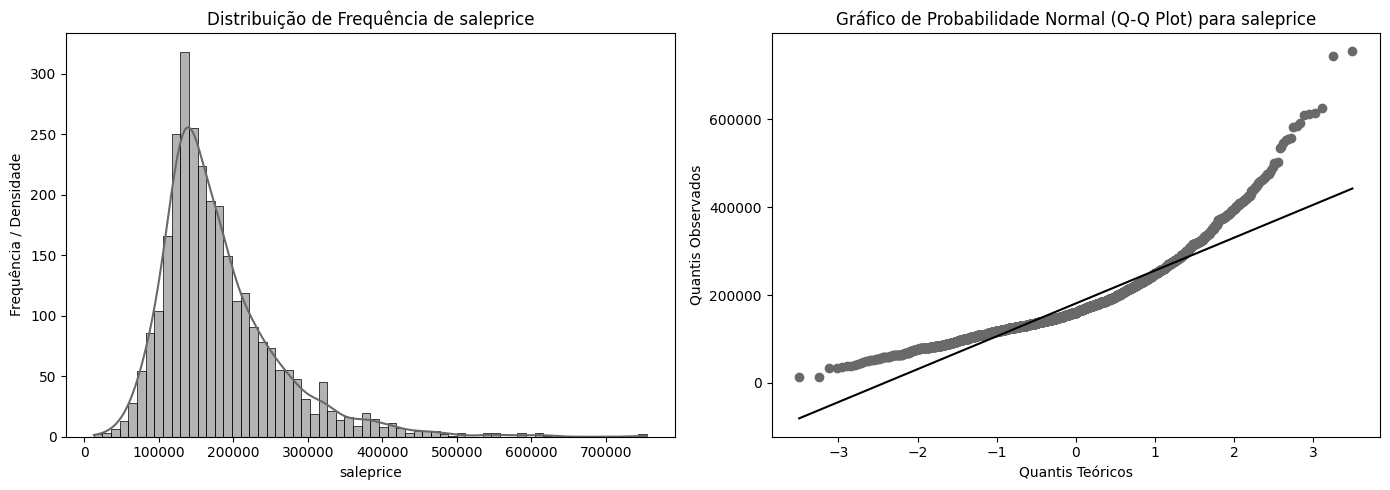

In [ ]:
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt

# Ajustado para 'saleprice' (minúsculo), correspondente ao seu arquivo CSV
variavel_alvo = 'saleprice'

# Garantia de que o df está disponível
if 'df' in globals():
    observacoes_validas = df[variavel_alvo].dropna()
    quant_validos = observacoes_validas.count()
    quant_nulos = df[variavel_alvo].isnull().sum()
    media = observacoes_validas.mean()
    variancia = observacoes_validas.var()

    print(f"--- Descrição Empírica: {variavel_alvo} ---")
    print(f"Quantidade de observações válidas: {quant_validos}")
    print(f"Quantidade de valores ausentes: {quant_nulos}")
    print(f"Média: {media:.4f}")
    print(f"Variância: {variancia:.4f}")

    # Representação Visual em tons neutros (sem cores chamativas)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Histograma com curva de densidade estimada (KDE) em tons de cinza
    sns.histplot(observacoes_validas, kde=True, ax=axes[0], color='dimgray', edgecolor='black')
    axes[0].set_title(f'Distribuição de Frequência de {variavel_alvo}')
    axes[0].set_xlabel(variavel_alvo)
    axes[0].set_ylabel('Frequência / Densidade')

    # Q-Q Plot com linha de referência preta
    stats.probplot(observacoes_validas, dist="norm", plot=axes[1])
    # Ajustando cores dos elementos do probplot para cinza/preto
    axes[1].get_lines()[0].set_color('dimgray')
    axes[1].get_lines()[1].set_color('black')
    axes[1].set_title(f'Gráfico de Probabilidade Normal (Q-Q Plot) para {variavel_alvo}')
    axes[1].set_xlabel('Quantis Teóricos')
    axes[1].set_ylabel('Quantis Observados')

    plt.tight_layout()
    plt.show()
else:
    print("Por favor, certifique-se de executar a célula acima que carrega os dados (df) antes de rodar esta análise!")